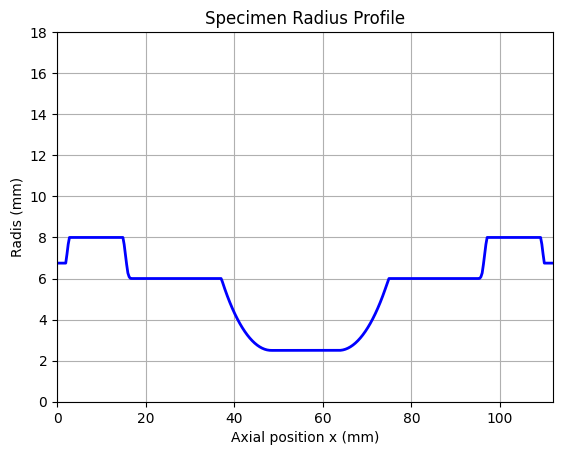

In [54]:
# //===== CEE292 - Scientific Machine Learning PINNs Project =====//

# PINNs Model for Thermo-mechanical Fatigue Testing of Inconel 718
# by Dat Le, Mechanics and Computation MS Candidate @ Stanford

# Paper Referenced for Data and Testing Methods:
# ASTM E-2369 TMF: Inter Laboratory Study (ILS) on Strain Controlled
# Thermo-Mechanical Fatigue Testing (Stefan Ripplinger et al. 2016)

# //==============================================================//
# //============= Start of Script for PINNs Project ==============//
# //==============================================================//

# Importing Python Libraries

import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# //==============================================================//
# //====== Importing Manually Cleaned Data from ILS Study ========//
# //==============================================================//

df_sample65 = pd.read_csv('/Cleaned_Sample65_Data.csv')

df_sample65 = df_sample65.dropna()

# //==============================================================//
# //========== Physical Parameters from Test Specimen ============//
# //==============================================================//

# Specimen Length
L = 112 # [mm]

# Number of Discrete Points
N = 400

# Discretized Specimen Length
x = torch.linspace(0, L, N).reshape(-1, 1).requires_grad_(True)

# Nominal Diameter of Specimen along X-Direction
DIA_x = np.array([])

# Piece-Wise Definition of Specimen Diameter Across Half-Length
for x_i in np.linspace(0, L/2, int(N/2)):

    # Segment Definitions Calculated with Desmos
    if  x_i <= 2:
        DIA = 13.5 # [mm]

    elif x_i > 2 and x_i < 2.721688:
        DIA = 13.5 + (2.5/0.721688) * (x_i-2) # [mm]

    elif x_i >= 2.721688 and x_i < 15:
        DIA = 16 # [mm]

    elif x_i >= 15 and x_i < 15.93027:
        DIA = 16 - (2.5/0.721688) * (x_i-15) # [mm]

    elif x_i >= 15.93027 and x_i < 16.721688:
        DIA = 14 - 2*np.sqrt(1-((x_i - (15.721688)) - 1)**2) # [mm]

    elif x_i >= 16.721688 and x_i < 37.19735:
        DIA = 12 # [mm]

    elif x_i >= 37.19735 and x_i < 48.5:
        DIA = 12 - 2 *  np.sqrt(400 - (x_i-48.5)**2) + 33 # [mm]

    elif x_i >= 48.5 and x_i < L/2:
        DIA = 5 # [mm]

    else:
        DIA = 5 # [mm]

    DIA_x = np.append(DIA_x, DIA)

# Mirror Half-Length Diameter and Convert to Tensor
DIA_x = torch.tensor(np.append(DIA_x, np.flip(DIA_x)), requires_grad=True)

# Define Radius as Half Diameter
RAD_x = 0.5*DIA_x

# Define Area with πr^2
Area_x = torch.pi*RAD_x**2

# Plotting Radius vs Length of Specimen
plt.figure()
plt.plot(x.detach().numpy(), RAD_x.detach().numpy(), 'b-', linewidth=2)

plt.xlabel("Axial position x (mm)")
plt.ylabel("Radis (mm)")
plt.title("Specimen Radius Profile")

plt.grid(True)
plt.xlim(0, 112)
plt.ylim(0, 18)

plt.show()

In [77]:
# Thermal Conductivity Value Based on Thermophysical Properties of
# Inconel 718 Alloy (A Sh Agazhanov et al 2019) | Eqns (9) & (10)
def Thermal_Conductivity(Temperature):

    k1 = 5.291 + 0.0152*Temperature + 1.382e-6*Temperature**2 # Eqn (9)
    k2 = ((24.6541-18.34)/(1173-800))*(Temperature - 800) + 18.34 # Linear Interpolation
    k3 = 11.75 + 0.0110*Temperature - 9.327e-7*Temperature**2 # Eqn (10)

    K = torch.where((Temperature >= 298) & (Temperature <= 800), k1,
        torch.where((Temperature >= 800) & (Temperature <= 1173), k2,
        torch.where((Temperature >= 1173) & (Temperature <= 1375), k3,
                    torch.nan)))

    return K/1000 # [W/mm*K]

# Thermal Expansion Value Based on Thermophysical Properties of
# Inconel 718 Alloy (A Sh Agazhanov et al 2019) | Eqns (4) & (5)
def Thermal_Expansion(Temperature):

    alpha1 = 10.747 + 0.01*Temperature - 4.2e-6*Temperature**2 # Eqn (4)
    alpha2 = ((20.01-15.9211)/(1180-760))*(Temperature - 760) + 15.92111 # Linear Interpolation
    alpha3 = 13.491 + 0.007*Temperature # Eqn (5)

    alpha = torch.where((Temperature >= 298) & (Temperature <= 760), alpha1,
            torch.where((Temperature >= 760) & (Temperature <= 1180), alpha2,
            torch.where((Temperature >= 1180) & (Temperature <= 1473), alpha3,
                    torch.nan)))

    return alpha * 1e-6 # [1/K]

# //==============================================================//
# //=== Defining Physics Residuals for (2) Governing Equations ===//
# //==============================================================//

# Physics/PDE Residual for Axial Deflection
def deflection_physics_residual(dudx_predicted, T_predicted, E_predicted, x_train, A_x):

    # First Gradient with Respect to x for A(x)
    A_x = A_x.detach().reshape(-1, 1)
    dAdx = torch.gradient(A_x.flatten(),spacing=(x_train.flatten(),))[0].reshape(-1, 1)

    # First Gradient with Respect to x for T(x)
    dTdx = torch.autograd.grad(T_predicted, x_train, grad_outputs=torch.ones_like(T_predicted), create_graph=True)[0]

    # First Gradient with Respect to T(x) for E(T(x))
    dEdT = torch.autograd.grad(E_predicted, T_predicted, grad_outputs=torch.ones_like(E_predicted), create_graph=True)[0]
    dEdx = dEdT*dTdx

    # Second Gradient with Respect to x for d2udx
    d2udx2 = torch.autograd.grad(dudx_predicted, x_train, grad_outputs=torch.ones_like(dudx_predicted), create_graph=True)[0]

    # Residual as Triple Product Rule Derivative of Deflection Equation
    residual = dEdx*A_x*dudx_predicted + E_predicted*dAdx*dudx_predicted + E_predicted*A_x*d2udx2

    return residual

# Physics/PDE Residual for Steady-State Thermal Diffusion
def temperature_residual(T_predicted, x_train, A_x, k_x):

    # First Gradient with Respect to x for A(x)
    dkdT = torch.autograd.grad(k_x, T_predicted, grad_outputs=torch.ones_like(T_predicted), create_graph=True)[0]

    # First Gradient with Respect to x for A(x)
    A_x = A_x.detach().reshape(-1, 1)
    dAdx = torch.gradient(A_x.flatten(),spacing=(x_train.flatten(),))[0].reshape(-1, 1)

    # Second gradient with respect to x for T(x)
    dTdx = torch.autograd.grad(T_predicted, x_train, grad_outputs=torch.ones_like(T_predicted), create_graph=True)[0]
    d2Tdx2 = torch.autograd.grad(dTdx, x_train, grad_outputs=torch.ones_like(dTdx), create_graph=True)[0]

    # Residual as Steady-State Temperature without Heat Input/Loss
    residual = dkdT*dTdx*A_x*dTdx + k_x*dAdx*dTdx + k_x*A_x*d2Tdx2

    return residual

# //==============================================================//
# //====== Defining Data Loss Function for Gage Temperature ======//
# //==============================================================//

def gage_temperature_loss(applied_gage_temperature, predicted_temperature, N, L):

    # Start of Gage on X-Axis
    x1 = 48.5 # [mm]
    idx1 = int(round((N-1)*x1/L))

    # End of Gage on X-Axis
    x2 = 63.5 # [mm]
    idx2 = int(round((N-1)*x2/L))

    # Gage Temperature Vector
    predicted_gage_temperature = predicted_temperature[idx1:idx2+1]
    gage_temperature = applied_gage_temperature * torch.ones(np.shape(predicted_gage_temperature))

    # Soft Enforcing Temperature Across Instrumented Gage
    criterion = nn.MSELoss()
    loss = criterion(gage_temperature, predicted_temperature[idx1:idx2+1])

    return loss

# //==============================================================//
# //======= Create Neural Network Class and PINNs Training =======//
# //==============================================================//

# Stiffness NN with Tanh Activation Function and 2 Inputs
class Tanh_NN_2_Input(nn.Module):
    def __init__(self, width, depth):

        super().__init__()
        layers = [nn.Linear(2, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers.extend([nn.Linear(width, width), nn.Tanh()])
        layers.append(nn.Linear(width, 1))
        self.network = nn.Sequential(*layers)

        # Setting Fatigue Coefficient as Trainable Parameter
        self.fatigue_rate = nn.Parameter(torch.tensor(-4.0))

    def forward(self, u, x, cycle_number):

        inputs = torch.cat([(u - 784.0)/500.0, x/L], dim=-1)
        decay = torch.exp(-F.softplus(self.fatigue_rate) * cycle_number / N_MAX)
        return F.softplus(self.network(inputs)) * decay

# Temperature NN with Tanh Activation Function and 1 Input
class Tanh_NN_1_Input(nn.Module):
    def __init__(self, width, depth):

        super().__init__()
        layers = [nn.Linear(1, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers.extend([nn.Linear(width, width), nn.Tanh()])
        layers.append(nn.Linear(width, 1))
        self.network = nn.Sequential(*layers)
        self.L = L
        self.dT_max = 486.0

    def forward(self, x):

        # Constrain Temperature between 298 K and 1375 K with Hard B.C. Contraint
        xi = x / self.L
        raw = self.network(2*xi - 1)
        bubble = 4*xi*(1 - xi)
        return bubble * self.dT_max * torch.tanh(raw)

# PINNs Training of 1-Input Tanh NN for Temperature Distributions
def Temperature_PINNs_Training(width, depth, x_training, N, L, A_x, T_gage, T_ref):

    Temperature_Distribution = Tanh_NN_1_Input(width, depth)
    optimizer = optim.Adam(Temperature_Distribution.parameters(), lr = 0.1)

    # Training Temperature Distribution
    for epoch in range(50):

        optimizer.zero_grad()
        T_predicted = Temperature_Distribution(x_training) + T_ref

        # Variation of Thermal Conductivity Along Length of Inconel 718
        k_x = Thermal_Conductivity(T_predicted)

        # Temperature Physics Residual
        residual = temperature_residual(T_predicted, x_training, A_x, k_x)

        # Measured Gage Temperature Data Loss
        data_loss = gage_temperature_loss(T_gage, T_predicted, N, L)

        # Total Loss Criterion as L_data + L_pde
        loss = 1000 * data_loss + 1 * torch.mean(residual**2)

        loss.backward()
        optimizer.step()

    with torch.no_grad():

        T_predicted = Temperature_Distribution(x_training).numpy().flatten() + T_ref

    return T_predicted, Temperature_Distribution

# //==============================================================//
# //====== Train PINN Temperature Distribution for Data Set ======//
# //==============================================================//

# Reference Temperature where Strain Normalized to Zero
T_ref = 784.05 # [K]

# Saving Temperature Distribution Models
Temperature_models = []

# Training Progress Counter for Temperature Vector
counter = 0

for gage_temperature in df_sample65.loc[:, 'Temperature [C]']:

    # Convert Gage Temperature from Celcius to Kelvin

    gage_temperature = gage_temperature + 273.15 # [K]

    T_prediction, Temperature_PINN = Temperature_PINNs_Training(33, 2, x, N, L, Area_x, gage_temperature, T_ref)

    # Printing Progress Every 10%
    counter = counter + 1

    if counter % 500 == 0:
        print("Training is at", counter, "of 4221")

    Temperature_models.append(Temperature_PINN)


Training is at 500 of 4221
Training is at 1000 of 4221
Training is at 1500 of 4221
Training is at 2000 of 4221
Training is at 2500 of 4221
Training is at 3000 of 4221
Training is at 3500 of 4221
Training is at 4000 of 4221


In [78]:
# //==============================================================//
# //========== Per-cycle Peak Strain and Stress Targets ==========//
# //==============================================================//

# row i lines up with Temperature_models[i]
df = df_sample65.reset_index(drop=True)

df['Total Strain [%]'] = df['Thermal Strain [%]'] + df['Mechanical Strain [%]']

# Row Index of Max Strains
peak_rows = df.groupby('Cycle Number')['Total Strain [%]'].idxmax()

# Row Index
peak_targets = {int(i): (df.loc[i, 'Total Strain [%]'] / 100.0, df.loc[i, 'Stress Maximum [MPa]'])
                for i in peak_rows}

# Scale to Inconel 718
E_SCALE = 1e5   # [MPa]

def stiffness_data_loss(Predicted_Stiffness, max_strain, max_stress):

    # Homogenized Stiffness Over Specimen Length
    mean_stiffness = torch.mean(Predicted_Stiffness) * E_SCALE # [MPa]

    # Predicted Max Stress at the Max-Strain Point in Cycle
    predicted_max_stress = mean_stiffness * max_strain # [MPa]

    # Compared in GPa
    target = torch.tensor(max_stress / 1000.0, dtype=torch.float32)
    return nn.MSELoss()(predicted_max_stress / 1000.0, target)

def Stiffness_PINNs_Training(width, depth, Temperature_models, Fatigue_cycles, x_training, N, L, A_x, T_ref):

    Stiffness = Tanh_NN_2_Input(width, depth)
    optimizer = optim.Adam(Stiffness.parameters(), lr = 0.01)

    M = len(Temperature_models)
    n_peaks = len(peak_targets)

    for epoch in range(30):

        optimizer.zero_grad()

        for i, (T_model, cycle) in enumerate(zip(Temperature_models, Fatigue_cycles)):

            T_predicted = T_model(x_training) + T_ref
            dudx_predicted = (T_predicted - T_ref) * Thermal_Expansion(T_predicted)
            Stiffness_predicted = Stiffness(T_predicted, x_training, float(cycle))

            # Physics Loss
            residual = deflection_physics_residual(dudx_predicted, T_predicted, Stiffness_predicted, x_training, A_x)
            physics_loss = torch.mean(residual**2) / M

            # BC Loss
            bc_loss = (Stiffness_predicted[0] - Stiffness_predicted[-1])**2

            # Data Loss at Max-Strain Intervals
            if i in peak_targets:
                max_strain, max_stress = peak_targets[i]
                loss = 1000 * bc_loss + physics_loss + 10.0 * stiffness_data_loss(Stiffness_predicted, max_strain, max_stress) / n_peaks

            else:
                loss = 1000 * bc_loss + physics_loss

            loss.backward()

        optimizer.step()

    return Stiffness

N_MAX = float(df_sample65['Cycle Number'].max())

Stiffness = Stiffness_PINNs_Training(33, 2, Temperature_models, df['Cycle Number'].values, x, N, L, Area_x, T_ref)

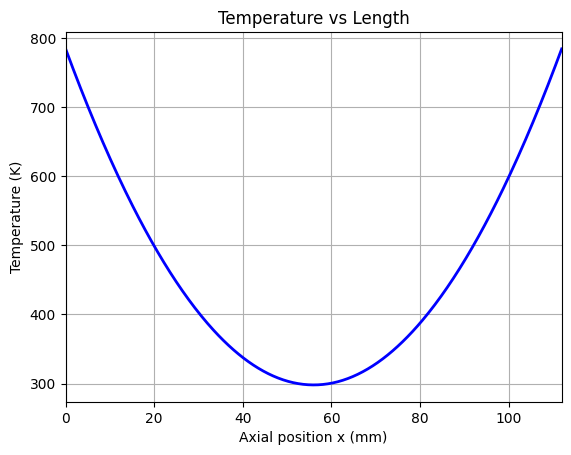

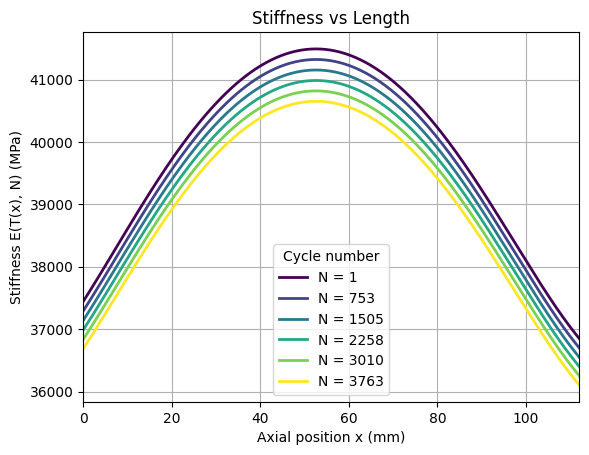

In [96]:
# //==============================================================//
# //===== Plotting Results of Temperature/Fatigue Dependence =====//
# //==============================================================//

T_model = Temperature_models[50]
T_plot = T_model(x) + T_ref

plt.figure()
plt.plot(x.detach().numpy(), T_plot.detach().numpy(), 'b-', linewidth=2)

plt.xlabel("Axial position x (mm)")
plt.ylabel("Temperature (K)")
plt.title("Temperature vs Length")

plt.grid(True)
plt.xlim(0, 112)
plt.show()

cycle_list = np.linspace(1, N_MAX, 6)
colors = plt.cm.viridis(np.linspace(0, 1, len(cycle_list)))

plt.figure()
with torch.no_grad():
    for c, col in zip(cycle_list, colors):
        E_plot = E_SCALE * Stiffness(T_plot, x, float(c))
        plt.plot(x.detach().numpy(), E_plot.numpy(), color=col, linewidth=2, label=f"N = {int(c)}")

plt.xlabel("Axial position x (mm)")
plt.ylabel("Stiffness E(T(x), N) (MPa)")
plt.title("Stiffness vs Length")
plt.legend(title="Cycle number", loc="best", frameon=True)

plt.grid(True)
plt.xlim(0, 112)
plt.show()

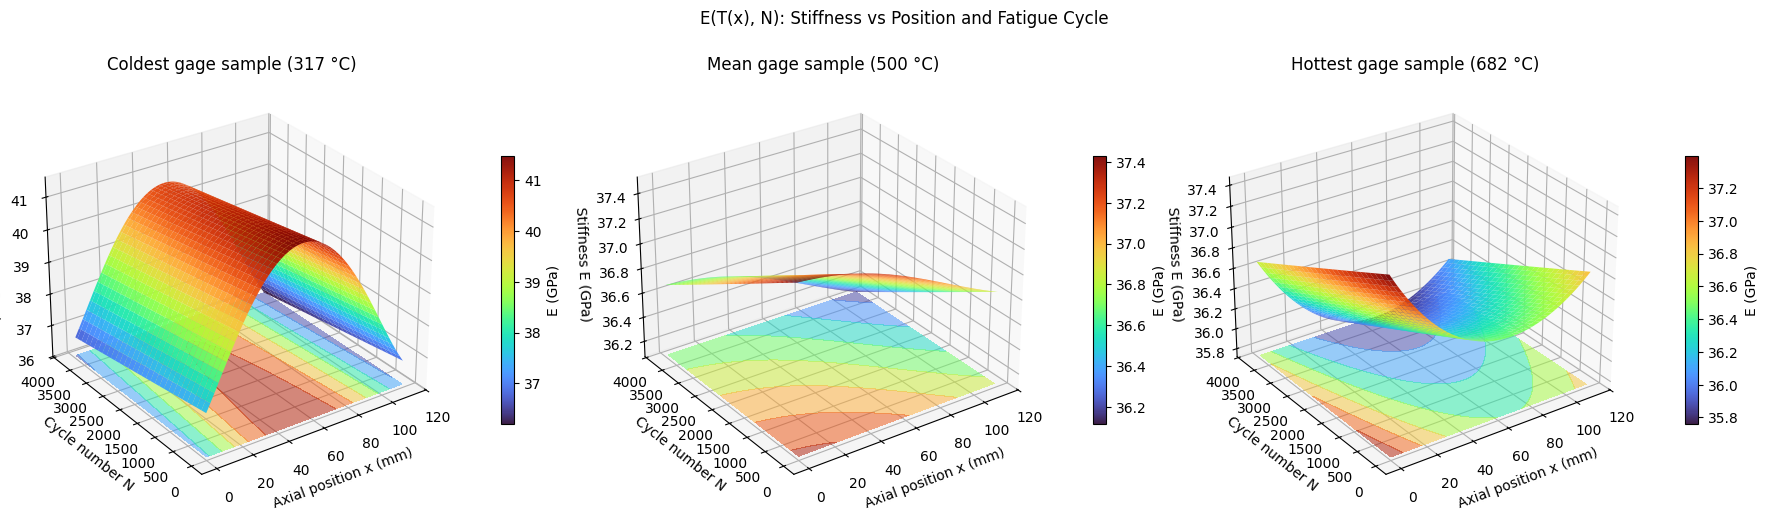

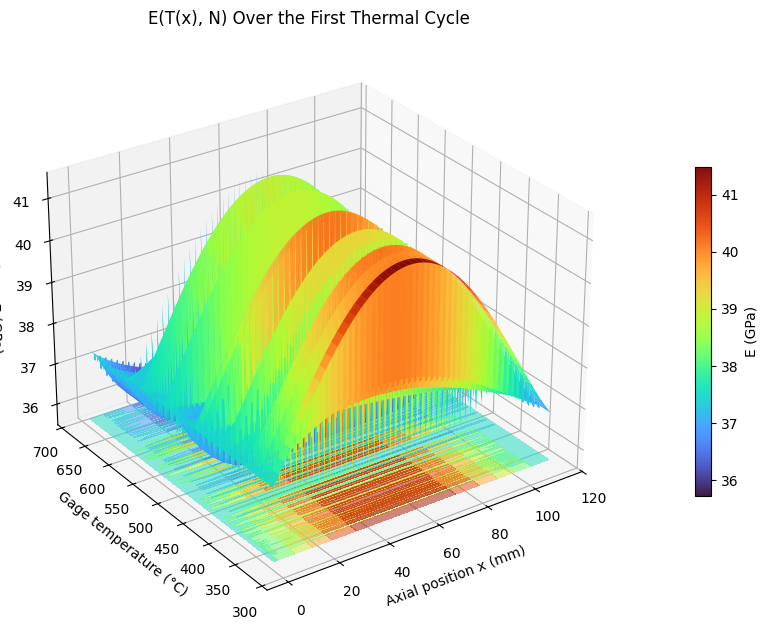

In [94]:
# //==============================================================//
# //============== 3-D Surface Plots of Stiffness E ==============//
# //==============================================================//

xs = x.detach().numpy().flatten()

def stiffness_surface(T_model, cycle_list):
    with torch.no_grad():
        T = T_model(x) + T_ref
        return np.stack([E_SCALE / 1e3 * Stiffness(T, x, float(c)).numpy().flatten()
                         for c in cycle_list])

def draw_surface(ax, X, Y, Z, ylabel, title):
    surf = ax.plot_surface(X, Y, Z, cmap='turbo', edgecolor='none', antialiased=True, alpha=0.95)
    ax.contourf(X, Y, Z, zdir='z', offset=Z.min(), cmap='turbo', alpha=0.5)
    ax.set_xlabel('Axial position x (mm)')
    ax.set_ylabel(ylabel)
    ax.set_zlabel('Stiffness E (GPa)')
    ax.set_title(title)
    ax.view_init(elev=28, azim=-125)
    plt.colorbar(surf, ax=ax, shrink=0.55, pad=0.1, label='E (GPa)')

# Plot 1
cycles = np.linspace(1, N_MAX, 60)
T_gage = df['Temperature [C]']
picks = {'Coldest gage sample': T_gage.idxmin(),
         'Mean gage sample':    (T_gage - T_gage.mean()).abs().idxmin(),
         'Hottest gage sample': T_gage.idxmax()}

fig = plt.figure(figsize=(18, 5.5))
X, Y = np.meshgrid(xs, cycles)
for k, (name, idx) in enumerate(picks.items()):
    ax = fig.add_subplot(1, 3, k + 1, projection='3d')
    Z = stiffness_surface(Temperature_models[idx], cycles)
    draw_surface(ax, X, Y, Z, 'Cycle number N', f'{name} ({T_gage[idx]:.0f} °C)')
plt.suptitle('E(T(x), N): Stiffness vs Position and Fatigue Cycle')
plt.tight_layout()
plt.show()

# Plot 2
first = df[df['Cycle Number'] == df['Cycle Number'].min()].sort_values('Temperature [C]')
Z = np.stack([stiffness_surface(Temperature_models[i], [df.loc[i, 'Cycle Number']])[0]
              for i in first.index])
X, Y = np.meshgrid(xs, first['Temperature [C]'].values)

fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(111, projection='3d')
draw_surface(ax, X, Y, Z, 'Gage temperature (°C)', 'E(T(x), N) Over the First Thermal Cycle')
plt.tight_layout()
plt.show()